# 05 · 数据管理与模型训练

接入模块四数据，完成数据快照、训练集构建、策略训练、闭环评测和世界模型推演。


In [1]:
import json
import uuid

from examples._display import (
    setup_notebook,
    show_animation,
    show_image,
    show_metrics,
)

PROJECT_ROOT, OUTPUT_DIR = setup_notebook("data_management_and_training")

from physrealx import ArtifactRef, PhysRealX, RunSpec
from physrealx.domain import TrainingSpec
from physrealx.integrations.datasets import dataset_bundle, load_snapshot

px = PhysRealX.open(PROJECT_ROOT / ".physrealx")
run_key = uuid.uuid4().hex[:12]

Python,3.11.15
解释器,/home/yxp/miniconda3/envs/PhysReal-X/bin/python


## 1. 仿真数据

读取模块四生成的多模态 Episode，完成质量校验、分组快照和训练集构建；随后训练并独立评测策略，同时导出 VLA、强化学习和世界模型接口所需的数据。


In [ ]:
upstream = json.loads(
    (PROJECT_ROOT / "examples/simulation_and_data_generation/output/results.json").read_text()
)
dataset_artifact = ArtifactRef.model_validate(upstream["simulation_dataset"])
evaluation_run = RunSpec.model_validate(upstream["evaluation_run"])
training_task = px.tasks.get(evaluation_run.task)
object_position_signal = next(
    signal.name
    for signal in training_task.observations
    if signal.name != "joint.position"
    and signal.name.startswith("joint.")
    and signal.name.endswith(".position")
)
object_velocity_signal = object_position_signal.removesuffix("position") + "velocity"


## 2. 数据接入


In [3]:
dataset = dataset_bundle(px.artifacts, dataset_artifact)
show_metrics(
    {
        "Episode": len(dataset.episodes),
        "成功 / 失败": f"{sum(row.success for row in dataset.episodes)} / "
        f"{sum(not row.success for row in dataset.episodes)}",
        "总帧数": dataset.total_steps,
        "观测信号": len(dataset.observation_schema),
        "动作维度": dataset.action_schema.shape[0],
    }
)

Episode,4
成功 / 失败,2 / 2
总帧数,804
观测信号,27
动作维度,7


## 3. 分组快照


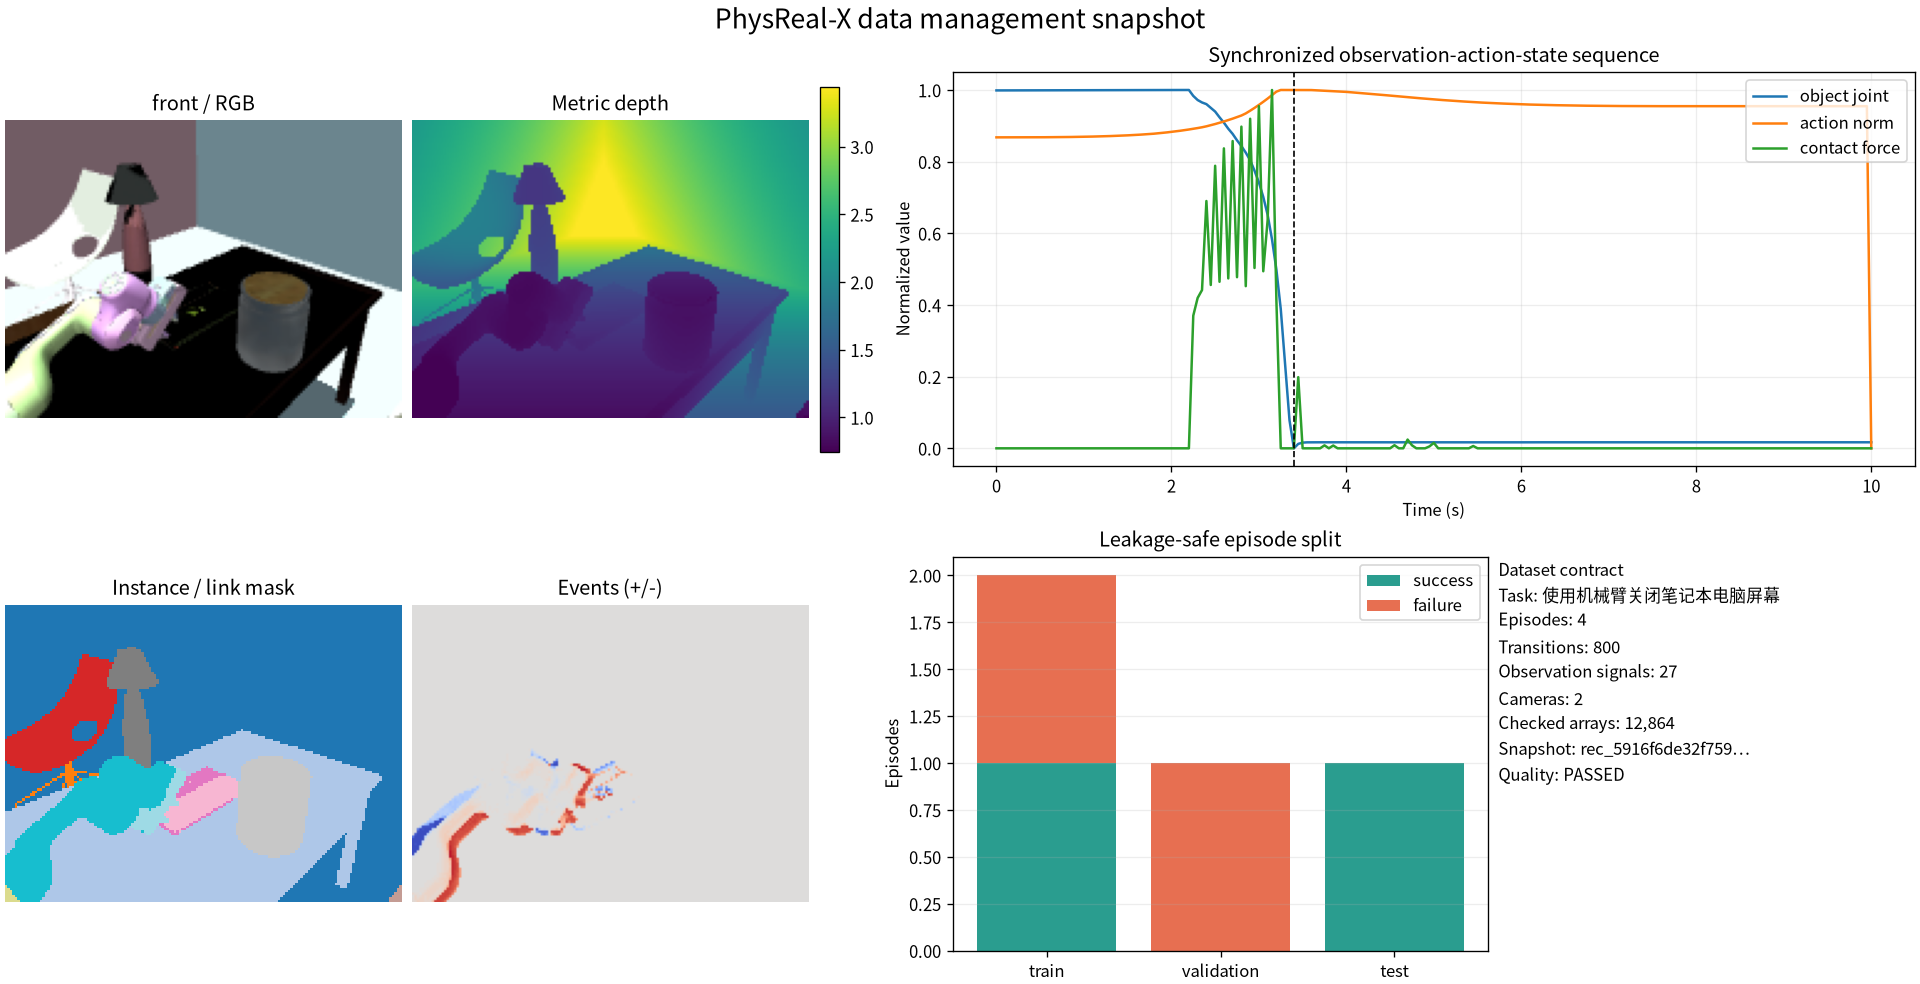

Train,2
Validation,1
Test,1
训练专家样本,1


In [4]:
operation = px.datasets.snapshot(
    dataset_artifact,
    method="episode_split",
    config={"seed": 2026, "stratify_success": True},
)
snapshot_ref = operation.output("snapshot")
snapshot_manifest_ref = operation.output("snapshot_manifest")
snapshot, _, partitions = load_snapshot(px.artifacts, snapshot_ref)
train_ref = px.datasets.training_subset(
    snapshot_ref,
    resource_id=f"laptop1.expert.train.{run_key}",
    required_tag="expert_demonstration",
)
dataset_preview = px.datasets.preview_snapshot(snapshot_ref, camera="front")
show_image(px.artifacts.get_bytes(dataset_preview))
show_metrics(
    {
        "Train": len(partitions["train"]),
        "Validation": len(partitions["validation"]),
        "Test": len(partitions["test"]),
        "训练专家样本": len(px.datasets.get(train_ref).episodes),
    }
)

## 4. 官方训练接口


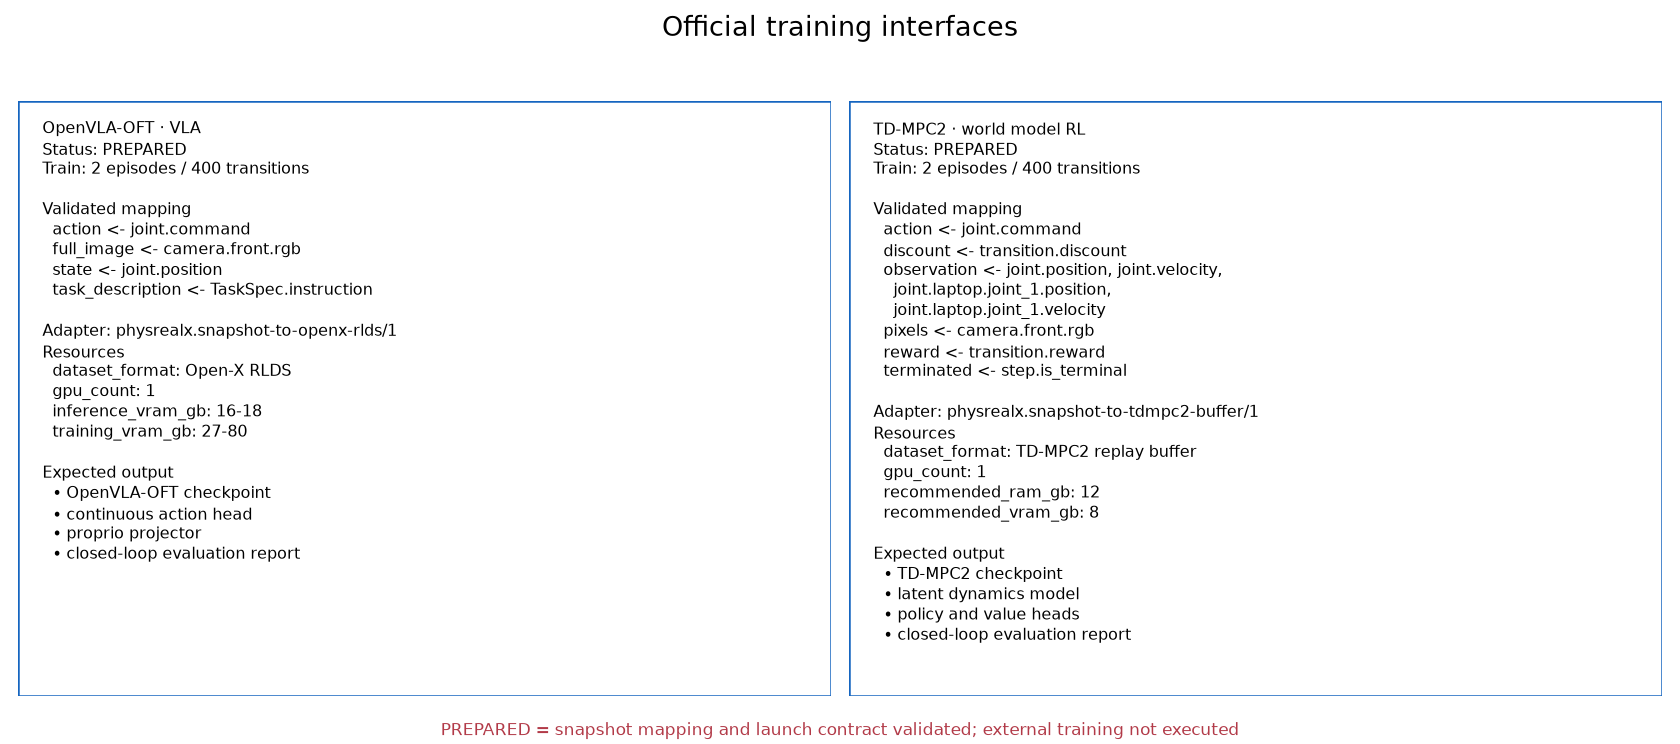

接口状态,PREPARED
固定官方项目,2


In [5]:
official_interfaces = {
    "openvla_oft": px.training.prepare_interface(
        snapshot_ref, method="openvla_oft", config={"gpu_count": 1}
    ),
    "td_mpc2": px.training.prepare_interface(
        snapshot_ref, method="td_mpc2", config={"gpu_count": 1, "observation": "state"}
    ),
}
interface_preview = px.training.preview_interfaces(tuple(official_interfaces.values()))
show_image(px.artifacts.get_bytes(interface_preview))
show_metrics({"接口状态": "PREPARED", "固定官方项目": len(official_interfaces)})


## 5. 策略训练


In [6]:
import torch

from physrealx.integrations.act import ACTTrainer

device = "cuda" if torch.cuda.is_available() else "cpu"
model_ref = px.training.submit(
    TrainingSpec(
        resource_id=f"laptop1.act.{run_key}",
        version="1.0.0",
        dataset=train_ref,
        trainer=ACTTrainer.descriptor.bind(
            config={
                "steps": 300,
                "device": device,
                "seed": 2026,
                "observation_signals": [
                    "joint.position",
                    "joint.velocity",
                    object_position_signal,
                    object_velocity_signal,
                ],
            }
        ),
    )
)
model = px.training.get_model(model_ref)
show_metrics({"训练设备": device, **model.metrics})

训练设备,cuda
final_loss,0.1713
initial_loss,0.9758
training_action_mae,0.003419
transitions,200


## 6. 闭环评测


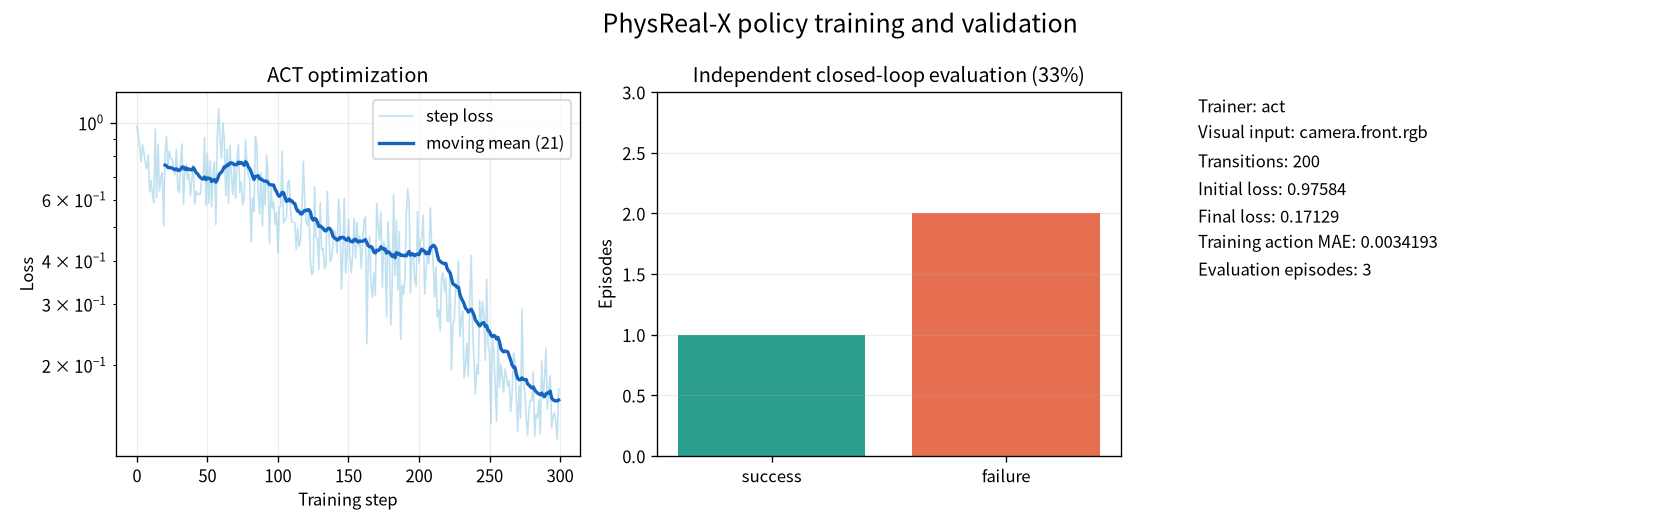

In [7]:
evaluation_ref = px.evaluations.submit(
    resource_id=f"laptop1.act.validation.{run_key}",
    version="1.0.0",
    model=model_ref,
    run=evaluation_run,
    episode_count=3,
    base_seed=91000,
)
evaluation = px.evaluations.get_report(evaluation_ref)
assert evaluation.metrics["episode_count"] == 3
policy_preview = px.training.preview_policy(model_ref, evaluation_ref)
show_image(px.artifacts.get_bytes(policy_preview))

## 7. 离线强化学习


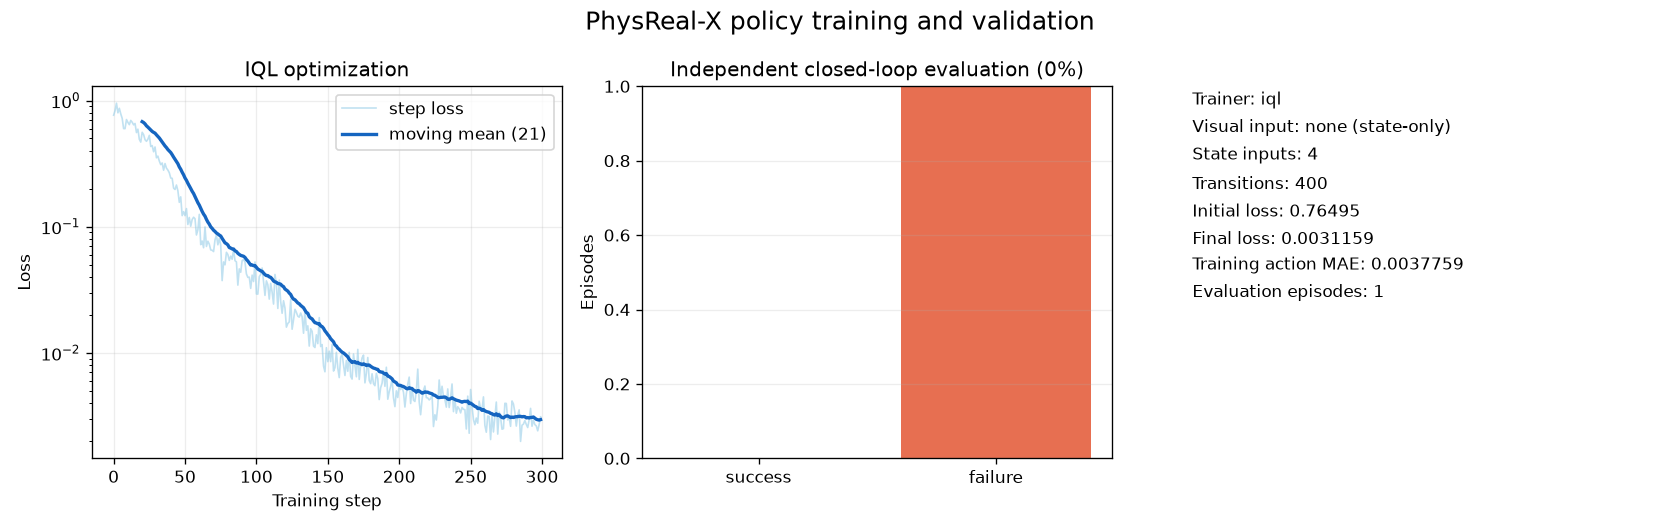

训练 Episode,2
训练动作 MAE,0.003776
闭环成功率,0


In [8]:
from physrealx.integrations.iql import IQLTrainer

rl_train_ref = px.datasets.training_subset(
    snapshot_ref,
    resource_id=f"laptop1.iql.train.{run_key}",
    selection="all_episodes",
)
iql_model_ref = px.training.submit(
    TrainingSpec(
        resource_id=f"laptop1.iql.{run_key}",
        version="1.0.0",
        dataset=rl_train_ref,
        trainer=IQLTrainer.descriptor.bind(
            config={
                "steps": 300,
                "device": device,
                "seed": 2026,
                "observation_signals": [
                    "joint.position",
                    "joint.velocity",
                    object_position_signal,
                    object_velocity_signal,
                ],
            }
        ),
    )
)
iql_evaluation_ref = px.evaluations.submit(
    resource_id=f"laptop1.iql.validation.{run_key}",
    version="1.0.0",
    model=iql_model_ref,
    run=evaluation_run,
    episode_count=1,
    base_seed=92000,
)
iql_model = px.training.get_model(iql_model_ref)
iql_evaluation = px.evaluations.get_report(iql_evaluation_ref)
iql_preview = px.training.preview_policy(iql_model_ref, iql_evaluation_ref)
show_image(px.artifacts.get_bytes(iql_preview))
show_metrics(
    {
        "训练 Episode": len(px.datasets.get(rl_train_ref).episodes),
        "训练动作 MAE": iql_model.metrics["training_action_mae"],
        "闭环成功率": iql_evaluation.success_rate,
    }
)


## 8. 世界模型训练


In [9]:
import math

encoder_ref = px.world_models.prepare_encoder(
    cache=PROJECT_ROOT / "examples/data_management_and_training/input/dinov2-encoder.json"
)
operation = px.world_models.train(
    snapshot_ref,
    encoder_ref,
    method="dino_wm",
    config={
        "device": device,
        "steps": 600,
        "history": 1,
        "training_horizon": 100,
        "evaluation_horizon": 100,
        "validation_interval": 200,
        "state_loss_weight": 5,
        "state_signals": [
            "joint.position",
            "joint.velocity",
            object_position_signal,
            object_velocity_signal,
        ],
    },
)
quality_metrics = dict(operation.metrics)
quality_pairs = {
    "状态 RMSE / persistence": (
        quality_metrics["test_normalized_state_rmse"],
        quality_metrics["test_persistence_normalized_state_rmse"],
    ),
    "潜变量 MSE / persistence": (
        quality_metrics["test_latent_mse"],
        quality_metrics["test_persistence_latent_mse"],
    ),
    "RGB MSE / persistence": (
        quality_metrics["test_rgb_mse"],
        quality_metrics["test_persistence_rgb_mse"],
    ),
}
if not all(math.isfinite(value) for pair in quality_pairs.values() for value in pair):
    raise RuntimeError("世界模型评测包含非有限值。")
state_error, state_baseline = quality_pairs["状态 RMSE / persistence"]
if state_error >= state_baseline:
    raise RuntimeError("世界模型状态预测未超过 persistence 基线。")
world_model_ref = operation.output("model")
world_report_ref = operation.output("training_report")
show_metrics(
    {
        label: value / baseline if baseline > 0 else float("nan")
        for label, (value, baseline) in quality_pairs.items()
    }
)


/mnt/53dad72e-a787-4c09-961e-eff73e08888e/yxp/Desktop/pingtaidajian/PhysReal-X/algorithms/dinov2/layers/swiglu_ffn.py:51: UserWarning: xFormers is not available (SwiGLU)
  warnings.warn("xFormers is not available (SwiGLU)")
/mnt/53dad72e-a787-4c09-961e-eff73e08888e/yxp/Desktop/pingtaidajian/PhysReal-X/algorithms/dinov2/layers/attention.py:33: UserWarning: xFormers is not available (Attention)
  warnings.warn("xFormers is not available (Attention)")
/mnt/53dad72e-a787-4c09-961e-eff73e08888e/yxp/Desktop/pingtaidajian/PhysReal-X/algorithms/dinov2/layers/block.py:40: UserWarning: xFormers is not available (Block)
  warnings.warn("xFormers is not available (Block)")


状态 RMSE / persistence,0.5084
潜变量 MSE / persistence,1
RGB MSE / persistence,1


## 9. 未来预测


In [10]:
import numpy as np

from physrealx.integrations._artifacts import read_array
from physrealx.integrations.world_model import WorldModelActions, WorldModelContext

held_out = [*partitions["test"], *partitions["validation"]]
test_episode = next((episode for episode in held_out if episode.success), None)
if test_episode is None:
    raise RuntimeError("分组快照没有保留成功 Episode，无法进行独立未来预测。")
test_summary = next(row for row in dataset.episodes if row.episode_id == test_episode.episode_id)
start_index, horizon = 0, 12
context_ref = px.artifacts.put_json(
    WorldModelContext(episode=test_summary, start_index=start_index).model_dump(
        mode="json", by_alias=True
    )
)
future_actions = [
    step.action.inline for step in test_episode.steps[start_index : start_index + horizon]
]
interval = test_episode.steps[1].timestamp_seconds - test_episode.steps[0].timestamp_seconds
actions_ref = px.artifacts.put_json(
    WorldModelActions(values=future_actions, interval_seconds=interval).model_dump(
        mode="json", by_alias=True
    )
)
operation = px.world_models.rollout(
    world_model_ref, context_ref, actions_ref, method="dino_wm", config={"device": device}
)
rollout = json.loads(px.artifacts.get_bytes(operation.output("rollout")))
predicted = read_array(px.artifacts, ArtifactRef.model_validate(rollout["states"]))
future_rgb = read_array(px.artifacts, ArtifactRef.model_validate(rollout["rgb"]))
truth = np.array(
    [
        step.observations["joint.position"].inline[0]
        for step in test_episode.steps[start_index + 1 : start_index + horizon + 1]
    ]
)
joint_rmse_rad = float(np.sqrt(np.mean((predicted[:, 0] - truth) ** 2)))
assert np.isfinite(predicted).all() and future_rgb.shape[0] == horizon
show_metrics({"短时预测步数": horizon, "关节 1 RMSE (rad)": joint_rmse_rad})

短时预测步数,12
关节 1 RMSE (rad),0.01092


## 10. 反事实对照


In [11]:
from physrealx import MethodCapability

held_action = list(test_episode.steps[0].action.inline)
changed_actions = [held_action for _ in range(100)]
changed_ref = px.artifacts.put_json(
    WorldModelActions(values=changed_actions, interval_seconds=interval)
)
operation = px.world_models.rollout(
    world_model_ref, context_ref, changed_ref, method="dino_wm", config={"device": device}
)
counterfactual_ref = operation.output("rollout")
changed = json.loads(px.artifacts.get_bytes(counterfactual_ref))
counterfactual = read_array(px.artifacts, ArtifactRef.model_validate(changed["states"]))
# Reuse the exact scene, task, backend and seed. Only future robot actions change.
counter_run = px.runs.submit(
    RunSpec(
        scene=test_episode.scene,
        task=test_episode.task,
        backend=test_episode.backend,
        policy=px.methods.bind(
            MethodCapability.POLICY_INFERENCE,
            "joint_sequence",
            config={"commands": changed_actions},
        ),
        episode_count=1,
        base_seed=test_episode.seed,
        stop_on_success=False,
        dataset_id=f"laptop1.counterfactual.{run_key}",
        dataset_version="1.0.0",
        record_signals=evaluation_run.record_signals,
        tags=("counterfactual_truth", test_episode.episode_id),
    )
)
counter_episode = px.runs.episodes(counter_run)[0]
counter_evaluation_ref = px.world_models.evaluate_rollout(
    counterfactual_ref, counter_episode, start_index=0
)
counter_evaluation = json.loads(px.artifacts.get_bytes(counter_evaluation_ref))
counter_truth = read_array(
    px.artifacts, ArtifactRef.model_validate(counter_evaluation["reference_states"])
)
if counterfactual.shape != counter_truth.shape or not np.isfinite(counterfactual).all():
    raise RuntimeError("反事实预测与独立 MuJoCo 真值不对齐。")
object_counterfactual = counter_evaluation["signals"][object_position_signal]
show_metrics(
    {
        "反事实时长 (s)": changed["timestamp_seconds"][-1],
        "物体关节 RMSE (rad)": object_counterfactual["rmse"][0],
        "相对 persistence": object_counterfactual["rmse_ratio"][0],
        "质量状态": object_counterfactual["status"][0],
    }
)


反事实时长 (s),5
物体关节 RMSE (rad),0.05727
相对 persistence,21.15
质量状态,BELOW_BASELINE


## 11. 五秒未来推演

从单帧起点生成 100 步状态与图像预测。


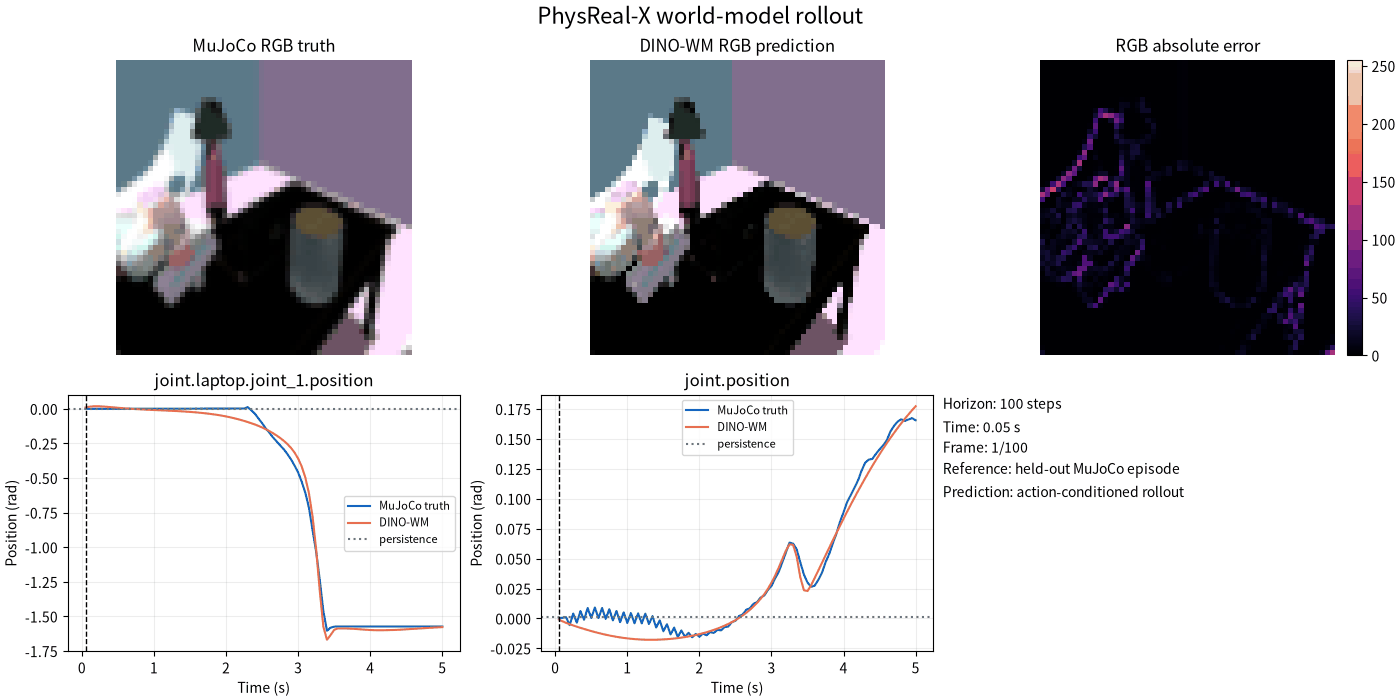

推演时长 (s),5
机器人关节平均 RMSE (rad),0.02556
物体关节 RMSE (rad),0.04515
物体关节 / persistence,0.04778
反事实物体关节 RMSE (rad),0.05727


In [12]:
five_second_steps = round(5.0 / interval)
assert len(test_episode.steps) > five_second_steps
continuation = [step.action.inline for step in test_episode.steps[:five_second_steps]]
long_actions = px.artifacts.put_json(
    WorldModelActions(values=continuation, interval_seconds=interval)
)
operation = px.world_models.rollout(
    world_model_ref, context_ref, long_actions, method="dino_wm", config={"device": device}
)
long_prediction_ref = operation.output("rollout")
long_prediction = json.loads(px.artifacts.get_bytes(long_prediction_ref))
long_evaluation_ref = px.world_models.evaluate_rollout(
    long_prediction_ref, test_episode, start_index=0
)
long_evaluation = json.loads(px.artifacts.get_bytes(long_evaluation_ref))
position_signals = ("joint.position", object_position_signal)
if any(
    not all(math.isfinite(value) for value in long_evaluation["signals"][name]["rmse"])
    for name in position_signals
):
    raise RuntimeError("长时预测评测包含非有限误差。")
world_model_preview = px.world_models.preview_rollout(
    long_prediction_ref,
    long_evaluation_ref,
    test_episode,
    camera="front",
    frames=8,
    fps=4,
)
show_animation(px.artifacts.get_bytes(world_model_preview))
object_long = long_evaluation["signals"][object_position_signal]
show_metrics(
    {
        "推演时长 (s)": long_prediction["timestamp_seconds"][-1],
        "机器人关节平均 RMSE (rad)": float(
            np.mean(long_evaluation["signals"]["joint.position"]["rmse"])
        ),
        "物体关节 RMSE (rad)": object_long["rmse"][0],
        "物体关节 / persistence": object_long["rmse_ratio"][0],
        "反事实物体关节 RMSE (rad)": object_counterfactual["rmse"][0],
    }
)


## 12. 结果导出


In [13]:
results = {
    "model": model_ref.model_dump(mode="json"),
    "offline_rl_model": iql_model_ref.model_dump(mode="json"),
    "offline_rl_dataset": rl_train_ref.model_dump(mode="json"),
    "offline_rl_evaluation": iql_evaluation_ref.model_dump(mode="json"),
    "openvla_oft_interface": official_interfaces["openvla_oft"].model_dump(mode="json"),
    "td_mpc2_interface": official_interfaces["td_mpc2"].model_dump(mode="json"),
    "world_model": world_model_ref.model_dump(mode="json"),
    "train_dataset": train_ref.model_dump(mode="json"),
    "snapshot": snapshot_ref.model_dump(mode="json"),
    "snapshot_manifest": snapshot_manifest_ref.model_dump(mode="json"),
    "dataset": dataset_artifact.model_dump(mode="json"),
    "evaluation": evaluation_ref.model_dump(mode="json"),
    "evaluation_run": evaluation_run.model_dump(mode="json"),
    "world_model_training": world_report_ref.model_dump(mode="json"),
    "long_prediction": long_prediction_ref.model_dump(mode="json"),
    "long_prediction_evaluation": long_evaluation_ref.model_dump(mode="json"),
    "counterfactual_prediction": counterfactual_ref.model_dump(mode="json"),
    "counterfactual_evaluation": counter_evaluation_ref.model_dump(mode="json"),
    "counterfactual_dataset": counter_run.result.dataset.model_dump(mode="json"),
    "dataset_preview": dataset_preview.model_dump(mode="json"),
    "policy_preview": policy_preview.model_dump(mode="json"),
    "offline_rl_preview": iql_preview.model_dump(mode="json"),
    "training_interface_preview": interface_preview.model_dump(mode="json"),
    "world_model_preview": world_model_preview.model_dump(mode="json"),
}
px.artifacts.export(
    OUTPUT_DIR,
    results,
    files={
        "dataset-preview.png": dataset_preview,
        "policy-training.png": policy_preview,
        "iql-training.png": iql_preview,
        "training-interfaces.png": interface_preview,
        "openvla-oft-interface.json": official_interfaces["openvla_oft"],
        "td-mpc2-interface.json": official_interfaces["td_mpc2"],
        "world-model-preview.gif": world_model_preview,
        "world-model.json": world_model_ref,
        "world-model-training.json": world_report_ref,
    },
)
print("结果索引:", OUTPUT_DIR / "results.json")


结果索引: /mnt/53dad72e-a787-4c09-961e-eff73e08888e/yxp/Desktop/pingtaidajian/PhysReal-X/examples/data_management_and_training/output/results.json
